In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("customer_support_tickets.csv")

In [3]:
df.head()

,Ticket ID,Customer Name,Customer Email,Customer Age,Customer Gender,Product Purchased,Date of Purchase,Ticket Type,Ticket Subject,Ticket Description,Ticket Status,Resolution,Ticket Priority,Ticket Channel,First Response Time,Time to Resolution,Customer Satisfaction Rating
0,1,Marisa Obrien,carrollallison@example.com,32,Other,GoPro Hero,2021-03-22,Technical issue,Product setup,I'm having an issue with the {product_purchase...,Pending Customer Response,NaN,Critical,Social media,2023-06-01 12:15:36,NaN,NaN
1,2,Jessica Rios,clarkeashley@example.com,42,Female,LG Smart TV,2021-05-22,Technical issue,Peripheral compatibility,I'm having an issue with the {product_purchase...,Pending Customer Response,NaN,Critical,Chat,2023-06-01 16:45:38,NaN,NaN
2,3,Christopher Robbins,gonzalestracy@example.com,48,Other,Dell XPS,2020-07-14,Technical issue,Network problem,I'm facing a problem with my {product_purchase...,Closed,Case maybe show recently my computer follow.,Low,Social media,2023-06-01 11:14:38,2023-06-01 18:05:38,3.0
3,4,Christina Dillon,bradleyolson@example.org,27,Female,Microsoft Office,2020-11-13,Billing inquiry,Account access,I'm having an issue with the {product_purchase...,Closed,Try capital clearly never color toward story.,Low,Social media,2023-06-01 07:29:40,2023-06-01 01:57:40,3.0
4,5,Alexander Carroll,bradleymark@example.com,67,Female,Autodesk AutoCAD,2020-02-04,Billing inquiry,Data loss,I'm having an issue with the {product_purchase...,Closed,West decision evidence bit.,Low,Email,2023-06-01 00:12:42,2023-06-01 19:53:42,1.0


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8469 entries, 0 to 8468
Data columns (total 17 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Ticket ID                     8469 non-null   int64  
 1   Customer Name                 8469 non-null   str    
 2   Customer Email                8469 non-null   str    
 3   Customer Age                  8469 non-null   int64  
 4   Customer Gender               8469 non-null   str    
 5   Product Purchased             8469 non-null   str    
 6   Date of Purchase              8469 non-null   str    
 7   Ticket Type                   8469 non-null   str    
 8   Ticket Subject                8469 non-null   str    
 9   Ticket Description            8469 non-null   str    
 10  Ticket Status                 8469 non-null   str    
 11  Resolution                    2769 non-null   str    
 12  Ticket Priority               8469 non-null   str    
 13  Ticket Channel

In [5]:
df.isnull().sum()

Ticket ID                          0
Customer Name                      0
Customer Email                     0
Customer Age                       0
Customer Gender                    0
Product Purchased                  0
Date of Purchase                   0
Ticket Type                        0
Ticket Subject                     0
Ticket Description                 0
Ticket Status                      0
Resolution                      5700
Ticket Priority                    0
Ticket Channel                     0
First Response Time             2819
Time to Resolution              5700
Customer Satisfaction Rating    5700
dtype: int64

In [6]:
df.columns

Index(['Ticket ID', 'Customer Name', 'Customer Email', 'Customer Age',
       'Customer Gender', 'Product Purchased', 'Date of Purchase',
       'Ticket Type', 'Ticket Subject', 'Ticket Description', 'Ticket Status',
       'Resolution', 'Ticket Priority', 'Ticket Channel',
       'First Response Time', 'Time to Resolution',
       'Customer Satisfaction Rating'],
      dtype='str')

In [7]:
print("Ticket Types:")
print(df['Ticket Type'].value_counts())

print("\nTicket Priorities:")
print(df['Ticket Priority'].value_counts())

Ticket Types:
Ticket Type
Refund request          1752
Technical issue         1747
Cancellation request    1695
Product inquiry         1641
Billing inquiry         1634
Name: count, dtype: int64

Ticket Priorities:
Ticket Priority
Medium      2192
Critical    2129
High        2085
Low         2063
Name: count, dtype: int64


In [8]:
df['Ticket Text'] = df['Ticket Subject'] + " " + df['Ticket Description']

In [9]:
df[['Ticket Subject', 'Ticket Description', 'Ticket Text']].head()

,Ticket Subject,Ticket Description,Ticket Text
0,Product setup,I'm having an issue with the {product_purchase...,Product setup I'm having an issue with the {pr...
1,Peripheral compatibility,I'm having an issue with the {product_purchase...,Peripheral compatibility I'm having an issue w...
2,Network problem,I'm facing a problem with my {product_purchase...,Network problem I'm facing a problem with my {...
3,Account access,I'm having an issue with the {product_purchase...,Account access I'm having an issue with the {p...
4,Data loss,I'm having an issue with the {product_purchase...,Data loss I'm having an issue with the {produc...


In [10]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer

In [11]:
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\kripa\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [12]:
stop_words = set(stopwords.words('english'))
stemmer = PorterStemmer()

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'[^a-z\s]', '', text)
    words = text.split()
    words = [stemmer.stem(word) for word in words if word not in stop_words]
    return ' '.join(words)

In [13]:
df['Cleaned Text'] = df['Ticket Text'].apply(clean_text)

In [14]:
df[['Ticket Text', 'Cleaned Text']].head()

,Ticket Text,Cleaned Text
0,Product setup I'm having an issue with the {pr...,product setup im issu productpurchas pleas ass...
1,Peripheral compatibility I'm having an issue w...,peripher compat im issu productpurchas pleas a...
2,Network problem I'm facing a problem with my {...,network problem im face problem productpurchas...
3,Account access I'm having an issue with the {p...,account access im issu productpurchas pleas as...
4,Data loss I'm having an issue with the {produc...,data loss im issu productpurchas pleas assist ...


In [15]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(max_features=5000)

X = tfidf.fit_transform(df['Cleaned Text'])

print("TF-IDF Shape:", X.shape)

TF-IDF Shape: (8469, 5000)


In [16]:
y_category = df['Ticket Type']
y_priority = df['Ticket Priority']

print("Categories:", y_category.nunique())
print("Priority Levels:", y_priority.nunique())

Categories: 5
Priority Levels: 4


In [17]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_cat_train, y_cat_test = train_test_split(
    X, y_category, test_size=0.2, random_state=42, stratify=y_category
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (6775, 5000)
Testing data: (1694, 5000)


In [18]:
from sklearn.linear_model import LogisticRegression

category_model = LogisticRegression(max_iter=1000)

category_model.fit(X_train, y_cat_train)

print("Ticket Category Model Training Completed!")

Ticket Category Model Training Completed!


In [19]:
y_cat_pred = category_model.predict(X_test)

print(y_cat_pred[:10])

['Refund request' 'Cancellation request' 'Cancellation request'
 'Product inquiry' 'Cancellation request' 'Technical issue'
 'Cancellation request' 'Product inquiry' 'Billing inquiry'
 'Technical issue']


In [20]:
from sklearn.metrics import accuracy_score, classification_report

accuracy = accuracy_score(y_cat_test, y_cat_pred)

print("Category Classification Accuracy:", accuracy * 100, "%")

print("\nClassification Report:")
print(classification_report(y_cat_test, y_cat_pred))

Category Classification Accuracy: 20.24793388429752 %

Classification Report:
                      precision    recall  f1-score   support

     Billing inquiry       0.20      0.18      0.19       327
Cancellation request       0.18      0.19      0.18       339
     Product inquiry       0.19      0.18      0.18       328
      Refund request       0.22      0.23      0.23       351
     Technical issue       0.21      0.23      0.22       349

            accuracy                           0.20      1694
           macro avg       0.20      0.20      0.20      1694
        weighted avg       0.20      0.20      0.20      1694



In [21]:
df[['Ticket Subject', 'Ticket Description', 'Ticket Type']].head(10)

,Ticket Subject,Ticket Description,Ticket Type
0,Product setup,I'm having an issue with the {product_purchase...,Technical issue
1,Peripheral compatibility,I'm having an issue with the {product_purchase...,Technical issue
2,Network problem,I'm facing a problem with my {product_purchase...,Technical issue
3,Account access,I'm having an issue with the {product_purchase...,Billing inquiry
4,Data loss,I'm having an issue with the {product_purchase...,Billing inquiry
5,Payment issue,I'm facing a problem with my {product_purchase...,Cancellation request
6,Refund request,I'm unable to access my {product_purchased} ac...,Product inquiry
7,Battery life,I'm having an issue with the {product_purchase...,Refund request
8,Installation support,I'm having an issue with the {product_purchase...,Technical issue
9,Payment issue,My {product_purchased} is making strange noise...,Refund request


In [22]:
X_subject = tfidf.fit_transform(df['Ticket Subject'].fillna(''))

X_train_sub, X_test_sub, y_train_sub, y_test_sub = train_test_split(
    X_subject, y_category,
    test_size=0.2,
    random_state=42,
    stratify=y_category
)

In [23]:
subject_model = LogisticRegression(max_iter=1000)

subject_model.fit(X_train_sub, y_train_sub)

subject_pred = subject_model.predict(X_test_sub)

print("Subject Model Accuracy:",
      accuracy_score(y_test_sub, subject_pred) * 100)

Subject Model Accuracy: 17.827626918536012


In [24]:
pd.crosstab(df['Ticket Subject'], df['Ticket Type'])

Ticket Type,Billing inquiry,Cancellation request,Product inquiry,Refund request,Technical issue
Ticket Subject,,,,,
Account access,103,92,107,108,99
Battery life,106,104,101,119,112
Cancellation request,82,103,85,109,108
Data loss,89,115,91,97,99
Delivery problem,115,114,109,107,116
Display issue,91,103,80,99,105
Hardware issue,100,109,106,129,103
Installation support,108,99,99,119,105
Network problem,95,102,113,107,122


In [25]:
print(df.groupby('Ticket Priority')['Ticket Type'].value_counts())

Ticket Priority  Ticket Type         
Critical         Refund request          444
                 Technical issue         439
                 Cancellation request    423
                 Billing inquiry         420
                 Product inquiry         403
High             Technical issue         458
                 Refund request          448
                 Product inquiry         399
                 Cancellation request    398
                 Billing inquiry         382
Low              Refund request          440
                 Cancellation request    414
                 Technical issue         413
                 Billing inquiry         398
                 Product inquiry         398
Medium           Cancellation request    460
                 Product inquiry         441
                 Technical issue         437
                 Billing inquiry         434
                 Refund request          420
Name: count, dtype: int64


In [26]:
print(df.groupby('Ticket Priority')['Ticket Subject'].nunique())

Ticket Priority
Critical    16
High        16
Low         16
Medium      16
Name: Ticket Subject, dtype: int64


In [27]:
X_train_p, X_test_p, y_pri_train, y_pri_test = train_test_split(
    X, y_priority,
    test_size=0.2,
    random_state=42,
    stratify=y_priority
)

In [28]:
priority_model = LogisticRegression(max_iter=1000)

priority_model.fit(X_train_p, y_pri_train)

print("Priority Model Training Completed!")

Priority Model Training Completed!


In [29]:
y_pri_pred = priority_model.predict(X_test_p)

In [30]:
print("Priority Classification Accuracy:",
      accuracy_score(y_pri_test, y_pri_pred) * 100)

print(classification_report(y_pri_test, y_pri_pred))

Priority Classification Accuracy: 25.737898465171195
              precision    recall  f1-score   support

    Critical       0.26      0.26      0.26       426
        High       0.25      0.23      0.24       417
         Low       0.26      0.25      0.25       413
      Medium       0.27      0.29      0.28       438

    accuracy                           0.26      1694
   macro avg       0.26      0.26      0.26      1694
weighted avg       0.26      0.26      0.26      1694



In [31]:
for i in range(5):
    print("Ticket:", i)
    print(df['Ticket Description'].iloc[i])
    print("-" * 80)

Ticket: 0
I'm having an issue with the {product_purchased}. Please assist.

Your billing zip code is: 71701.

We appreciate that you have requested a website address.

Please double check your email address. I've tried troubleshooting steps mentioned in the user manual, but the issue persists.
--------------------------------------------------------------------------------
Ticket: 1
I'm having an issue with the {product_purchased}. Please assist.

If you need to change an existing product.

I'm having an issue with the {product_purchased}. Please assist.

If The issue I'm facing is intermittent. Sometimes it works fine, but other times it acts up unexpectedly.
--------------------------------------------------------------------------------
Ticket: 2
I'm facing a problem with my {product_purchased}. The {product_purchased} is not turning on. It was working fine until yesterday, but now it doesn't respond.

1.8.3 I really I'm using the original charger that came with my {product_purchase

In [32]:
df['Improved Text'] = (
    df['Ticket Subject'].fillna('') + ' ' +
    df['Ticket Subject'].fillna('') + ' ' +
    df['Ticket Description'].fillna('')
)

In [33]:
tfidf_new = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    sublinear_tf=True
)

X_new = tfidf_new.fit_transform(df['Improved Text'])

In [34]:
X_train_new, X_test_new, y_train_new, y_test_new = train_test_split(
    X_new, y_category,
    test_size=0.2,
    random_state=42,
    stratify=y_category
)

In [35]:
improved_category_model = LogisticRegression(max_iter=1000)

improved_category_model.fit(X_train_new, y_train_new)

print("Improved Category Model Training Completed!")

Improved Category Model Training Completed!


In [36]:
y_pred_new = improved_category_model.predict(X_test_new)

print("Improved Category Accuracy:",
      accuracy_score(y_test_new, y_pred_new) * 100)

Improved Category Accuracy: 21.723730814639904


In [37]:
X_train_p_new, X_test_p_new, y_train_p_new, y_test_p_new = train_test_split(
    X_new, y_priority,
    test_size=0.2,
    random_state=42,
    stratify=y_priority
)

In [38]:
improved_priority_model = LogisticRegression(max_iter=1000)

improved_priority_model.fit(X_train_p_new, y_train_p_new)

print("Improved Priority Model Training Completed!")

Improved Priority Model Training Completed!


In [39]:
y_pred_p_new = improved_priority_model.predict(X_test_p_new)

In [40]:
print("Improved Priority Accuracy:",
      accuracy_score(y_test_p_new, y_pred_p_new) * 100)

print(classification_report(y_test_p_new, y_pred_p_new))

Improved Priority Accuracy: 26.15112160566706
              precision    recall  f1-score   support

    Critical       0.26      0.26      0.26       426
        High       0.27      0.23      0.25       417
         Low       0.27      0.27      0.27       413
      Medium       0.26      0.28      0.27       438

    accuracy                           0.26      1694
   macro avg       0.26      0.26      0.26      1694
weighted avg       0.26      0.26      0.26      1694



In [41]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

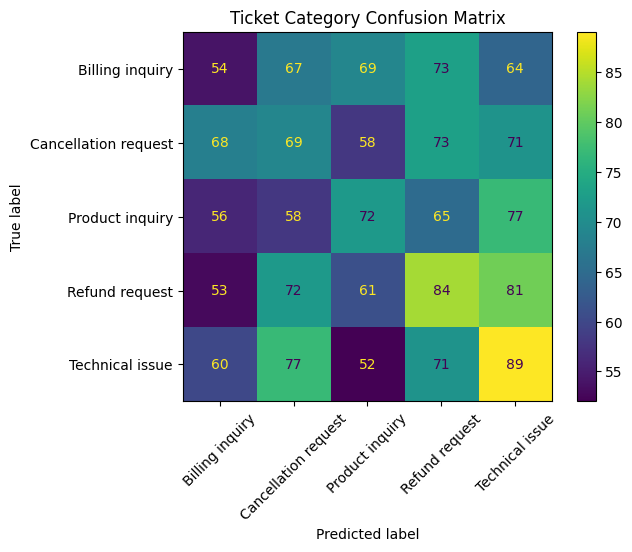

In [42]:
cm = confusion_matrix(y_test_new, y_pred_new)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=improved_category_model.classes_
)

disp.plot(xticks_rotation=45)
plt.title("Ticket Category Confusion Matrix")
plt.show()

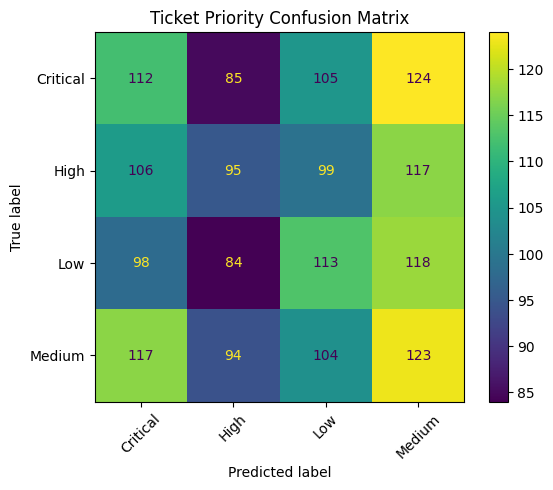

In [43]:
cm_priority = confusion_matrix(y_test_p_new, y_pred_p_new)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_priority,
    display_labels=improved_priority_model.classes_
)

disp.plot(xticks_rotation=45)
plt.title("Ticket Priority Confusion Matrix")
plt.show()

In [45]:
def classify_ticket(subject, description):

    text = subject + " " + subject + " " + description

    cleaned = clean_text(text)

    features = tfidf_new.transform([cleaned])

    category = improved_category_model.predict(features)[0]

    priority = improved_priority_model.predict(features)[0]

    print("Ticket Classification Results")
    print("------------------------------")
    print("Ticket Subject:", subject)
    print("Predicted Category:", category)
    print("Predicted Priority:", priority)

In [46]:
classify_ticket(
    "Payment issue",
    "I was charged twice for my recent purchase. Please check my payment and refund the extra amount."
)

Ticket Classification Results
------------------------------
Ticket Subject: Payment issue
Predicted Category: Cancellation request
Predicted Priority: Medium


In [47]:
results = pd.DataFrame({
    'Model': [
        'Original Category Model',
        'Subject Only Model',
        'Improved Category Model',
        'Original Priority Model',
        'Improved Priority Model'
    ],
    'Accuracy (%)': [
        20.25,
        17.83,
        21.72,
        25.74,
        26.15
    ]
})

print(results)

                     Model  Accuracy (%)
0  Original Category Model         20.25
1       Subject Only Model         17.83
2  Improved Category Model         21.72
3  Original Priority Model         25.74
4  Improved Priority Model         26.15


In [48]:
results.to_csv("model_performance_results.csv", index=False)

print("Model performance results saved successfully!")

Model performance results saved successfully!
